# 🛒 Online Shoppers Purchasing Intention — Classification Track (Part A)
**23CSE301 Machine Learning Capstone | Review 1**

---

## Objective
Predict whether an online shopping session will result in a **purchase (`Revenue = True`)** using five classification algorithms (Part A).

This notebook covers the complete Review-1 Classification Part A pipeline:

1. Dataset loading & audit  
2. Exploratory Data Analysis (EDA)  
3. Data cleaning, feature engineering & preprocessing  
4. Training 5 Part-A classification models  
5. Evaluation (Accuracy, Weighted F1, Confusion Matrix)  
6. Preliminary comparison table  

**Dataset:** Online Shoppers Purchasing Intention (12,330 sessions, 18 features)  
**Target:** `Revenue` (binary: True/False)  
**`random_state = 42` used throughout for reproducibility.**

---
## 0 — Imports & Configuration

In [1]:
# Standard library
import warnings
warnings.filterwarnings('ignore')

# Data manipulation
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn — preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Scikit-learn — models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.svm import SVC

# Scikit-learn — metrics
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

# Scikit-learn — tuning
from sklearn.model_selection import GridSearchCV, cross_val_score

# Plotting style
sns.set_theme(style='whitegrid', palette='Set2', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110
COLORS = sns.color_palette('Set2')

RANDOM_STATE = 42
print('All libraries imported successfully.')

All libraries imported successfully.


---
## 1 — Dataset Loading & Audit

We load the Online Shoppers dataset and perform a full audit:
shape, data types, missing-value counts, and the class distribution of `Revenue`.

In [2]:
# ------------------------------------------------------------------
# 1.1  Load dataset
# ------------------------------------------------------------------
import os
DATA_PATH = r"../data/online_shoppers_intention.csv" if os.path.exists(r"../data/online_shoppers_intention.csv") else r"../online+shoppers+purchasing+intention+dataset (Classification)/online_shoppers_intention.csv"
df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns")


Dataset loaded: 12,330 rows × 18 columns


In [3]:
# ------------------------------------------------------------------
# 1.2  Shape, dtypes, first few rows
# ------------------------------------------------------------------
print('=== SHAPE ===')
print(f'Rows: {df.shape[0]:,}   Columns: {df.shape[1]}')
print()
print('=== DATA TYPES ===')
print(df.dtypes)
print()
print('=== TYPE SUMMARY ===')
print(df.dtypes.value_counts())
print()
print('=== FIRST 5 ROWS ===')
df.head()

=== SHAPE ===
Rows: 12,330   Columns: 18

=== DATA TYPES ===
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

=== TYPE SUMMARY ===
int64      7
float64    7
str        2
bool       2
Name: count, dtype: int64

=== FIRST 5 ROWS ===


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
# ------------------------------------------------------------------
# 1.3  Missing value audit
# ------------------------------------------------------------------
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print('Missing value audit:')
print(missing_df[missing_df['Missing Count'] > 0])
print(f'\nTotal missing values: {missing.sum()}')
if missing.sum() == 0:
    print('✔ No missing values found — dataset is complete.')

Missing value audit:
Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []

Total missing values: 0
✔ No missing values found — dataset is complete.


=== Revenue (Target) Distribution ===
         Count  Percentage
Revenue                   
False    10422       84.53
True      1908       15.47


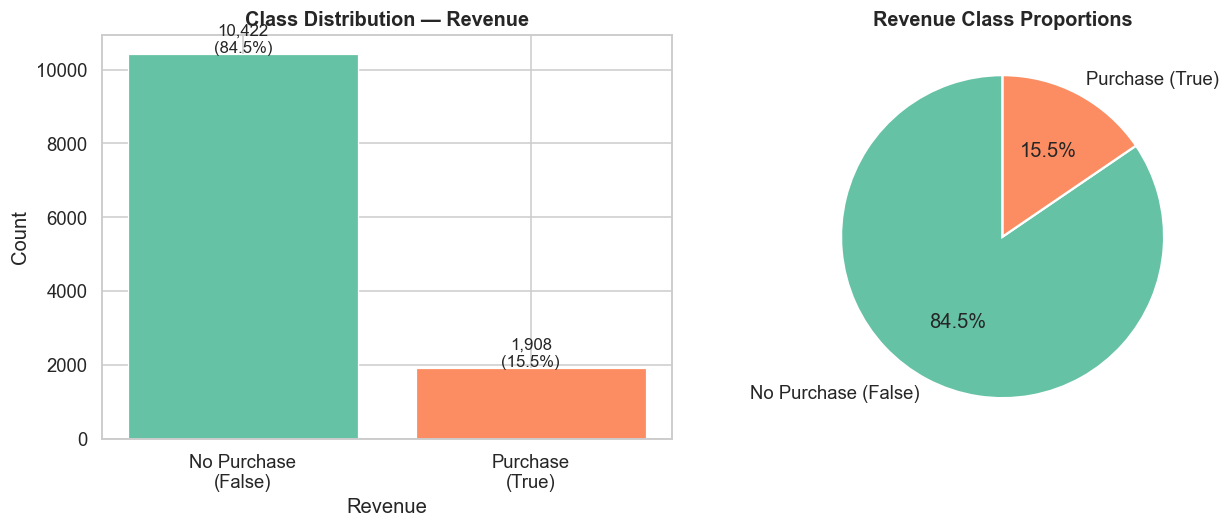

In [5]:
# ------------------------------------------------------------------
# 1.4  Class (target) distribution
# ------------------------------------------------------------------
print('=== Revenue (Target) Distribution ===')
vc = df['Revenue'].value_counts()
vc_pct = df['Revenue'].value_counts(normalize=True) * 100
dist_df = pd.DataFrame({'Count': vc, 'Percentage': vc_pct.round(2)})
print(dist_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
axes[0].bar(['No Purchase\n(False)', 'Purchase\n(True)'],
            [vc[False], vc[True]],
            color=[COLORS[0], COLORS[1]], edgecolor='white', linewidth=0.8)
axes[0].set_title('Class Distribution — Revenue', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('Revenue')
for i, v in enumerate([vc[False], vc[True]]):
    axes[0].text(i, v + 50, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', fontsize=11)

# Pie chart
axes[1].pie([vc[False], vc[True]],
            labels=['No Purchase (False)', 'Purchase (True)'],
            colors=[COLORS[0], COLORS[1]],
            autopct='%1.1f%%', startangle=90,
            wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[1].set_title('Revenue Class Proportions', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

**📝 Observation (Class Distribution):**  
- The dataset is **significantly imbalanced**: ~84.5% non-purchase sessions vs ~15.5% purchase sessions.  
- This means a naïve classifier that always predicts 'No Purchase' would achieve 84.5% accuracy — making **accuracy alone a misleading metric**.  
- Weighted F1-score is therefore more informative for evaluating classifier performance.  
- **Stratified train/test split** is essential to preserve this class ratio in both subsets.

---
## 2 — Exploratory Data Analysis (EDA)

Comprehensive EDA covering all 18 features with:
- Distribution plots for every feature
- Correlation heatmap
- Feature-target relationship plots

In [6]:
# ------------------------------------------------------------------
# 2.1  Identify feature types
# ------------------------------------------------------------------
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'bool']).columns.tolist()

# Remove target from lists
if 'Revenue' in num_cols:  num_cols.remove('Revenue')
if 'Revenue' in cat_cols:  cat_cols.remove('Revenue')

print(f'Numerical features : {len(num_cols)} → {num_cols}')
print(f'Categorical/Bool features: {len(cat_cols)} → {cat_cols}')

Numerical features : 14 → ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Categorical/Bool features: 3 → ['Month', 'VisitorType', 'Weekend']


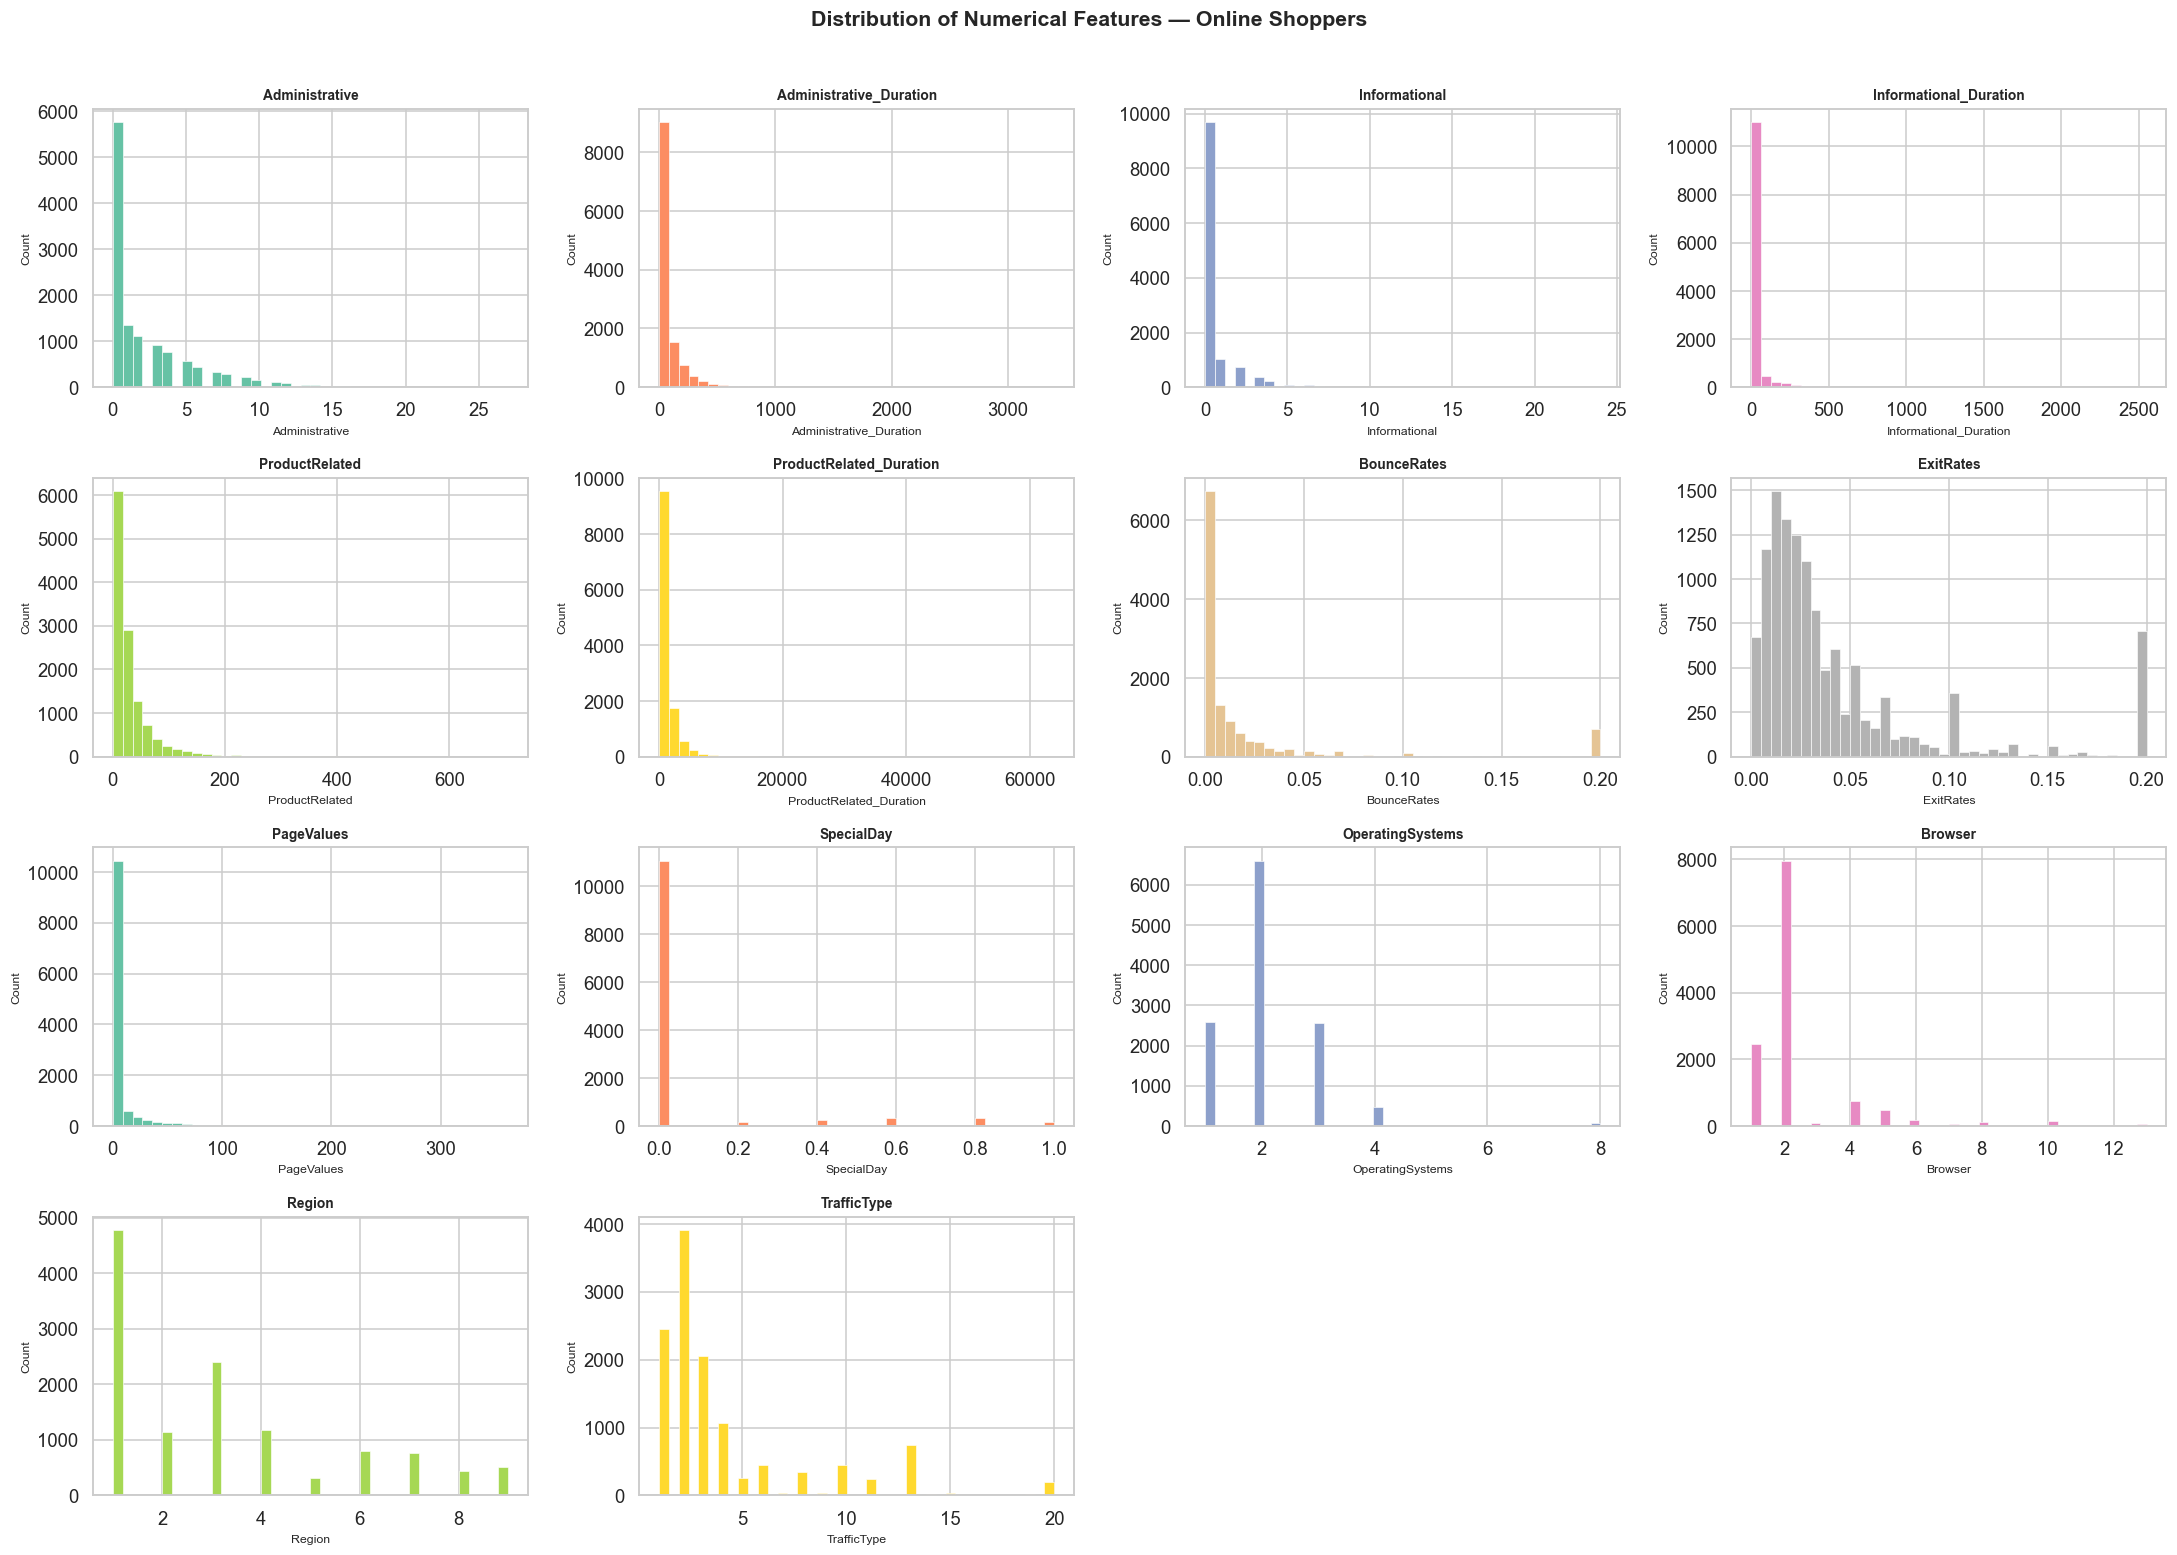

In [7]:
# ------------------------------------------------------------------
# 2.2  Distribution plots — Numerical features
# ------------------------------------------------------------------
n_num = len(num_cols)
ncols = 4
nrows = (n_num + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 3.5))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(df[col].dropna(), bins=40,
                 color=COLORS[i % len(COLORS)], edgecolor='white', linewidth=0.4)
    axes[i].set_title(col, fontsize=9, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=8)
    axes[i].set_ylabel('Count', fontsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Distribution of Numerical Features — Online Shoppers',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**📝 Observation (Numerical Distributions):**  
- `Administrative`, `Informational`, and `ProductRelated` page counts are **heavily right-skewed** — most sessions visit very few pages, with a long tail of highly engaged visitors.  
- `BounceRates` and `ExitRates` are skewed toward zero — most visitors don't bounce immediately, indicating engagement.  
- `PageValues` is nearly zero for most sessions but has a long tail — high `PageValues` likely strongly predicts a purchase.  
- `SpecialDay` is mostly 0, indicating most visits don't occur near special commercial days.

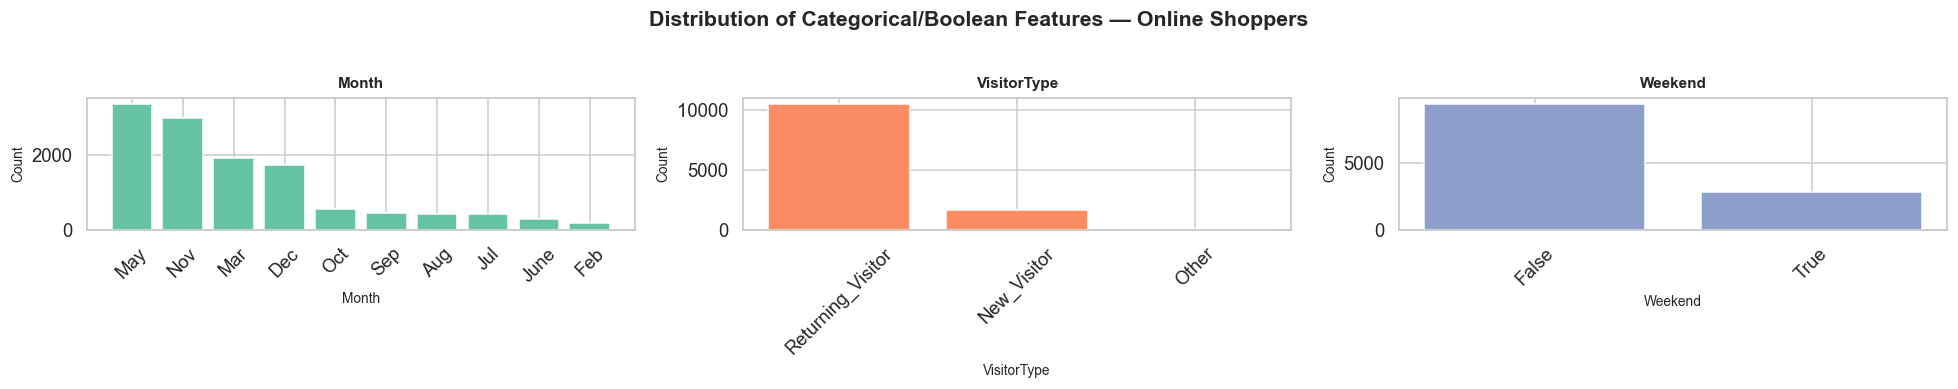

In [8]:
# ------------------------------------------------------------------
# 2.3  Distribution plots — Categorical / Boolean features
# ------------------------------------------------------------------
n_cat = len(cat_cols)
ncols_c = 3
nrows_c = (n_cat + ncols_c - 1) // ncols_c

fig, axes = plt.subplots(nrows_c, ncols_c, figsize=(18, nrows_c * 3.5))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    vc = df[col].value_counts()
    axes[i].bar(vc.index.astype(str), vc.values,
                color=COLORS[i % len(COLORS)], edgecolor='white')
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=9)
    axes[i].set_ylabel('Count', fontsize=9)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Distribution of Categorical/Boolean Features — Online Shoppers',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**📝 Observation (Categorical Distributions):**  
- `Month` shows a non-uniform distribution — `May`, `November`, and `March` have the highest session counts.  
  November likely corresponds to Black Friday/Cyber Monday seasonal peaks.  
- `VisitorType` is dominated by `Returning_Visitor` (~85%), suggesting the majority of shoppers are repeat visitors.  
- `Weekend` is a binary flag where weekdays (~77%) outnumber weekends, reflecting typical browsing patterns.  
- `OperatingSystems`, `Browser`, `Region`, and `TrafficType` are nominal integer codes that should be treated as categorical.

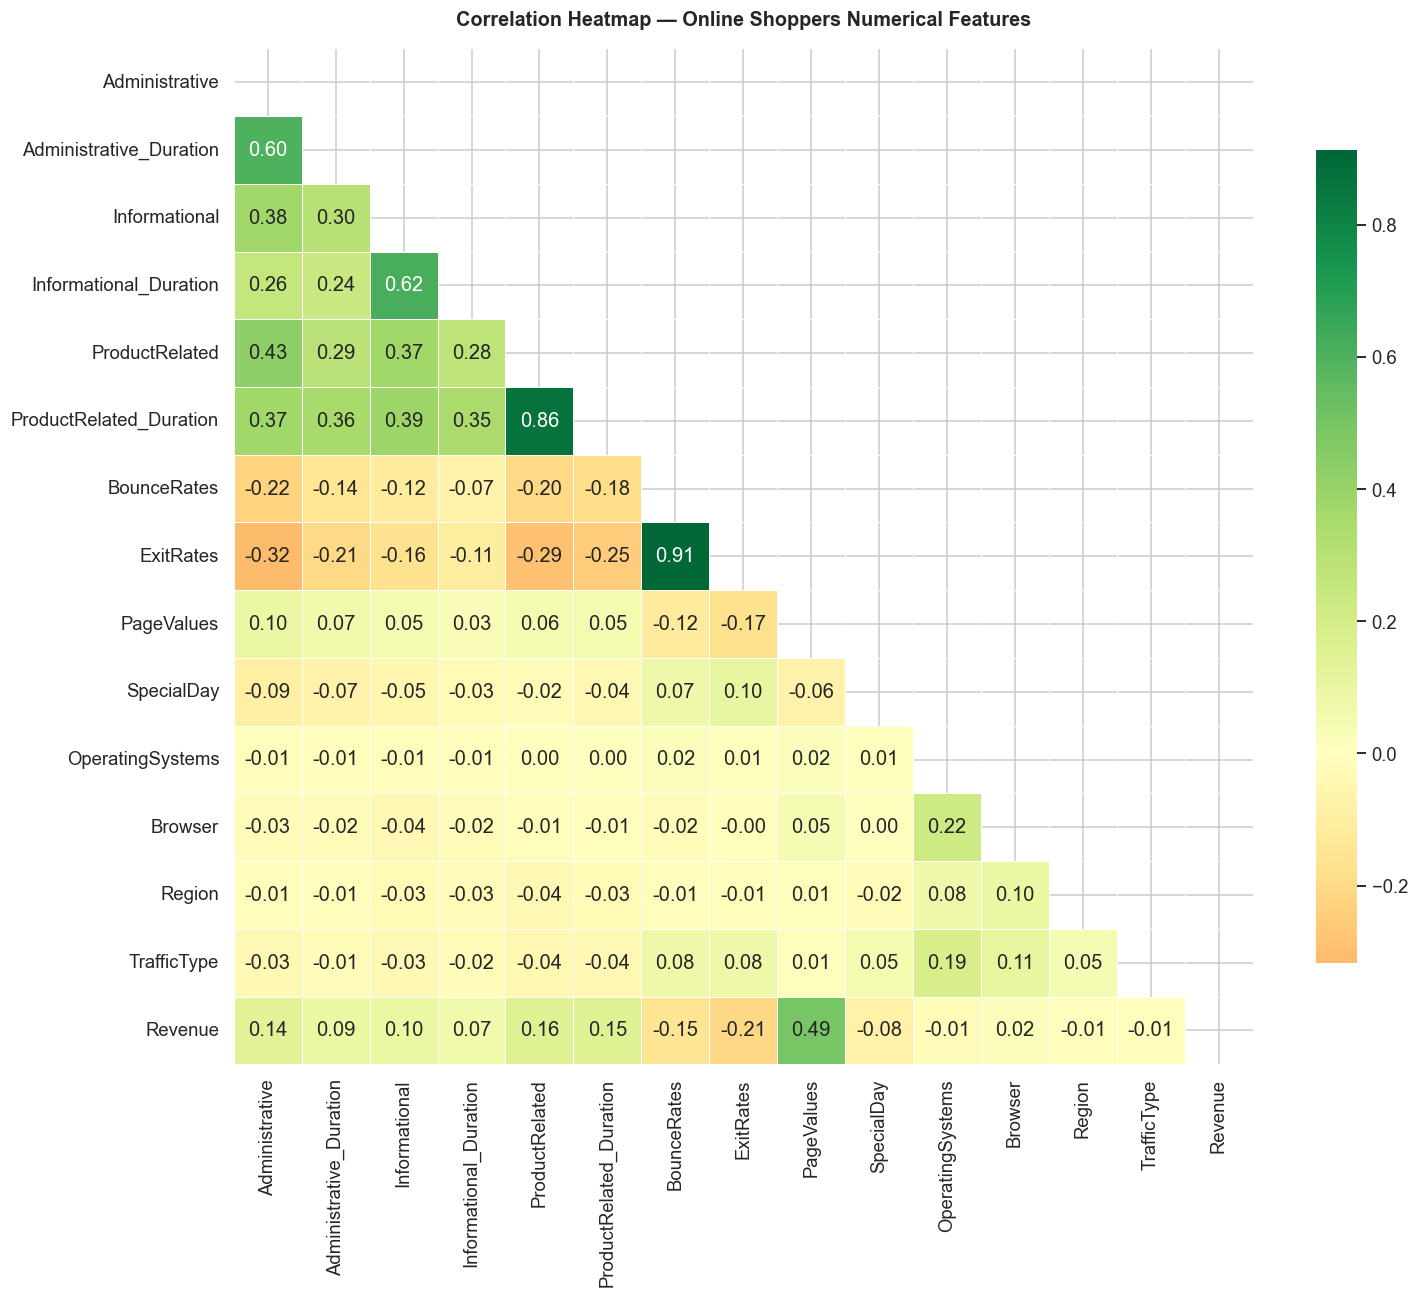

In [9]:
# ------------------------------------------------------------------
# 2.4  Correlation heatmap — Numerical features
# ------------------------------------------------------------------
df_corr = df[num_cols].copy()
# Add Revenue as 0/1 for correlation
df_corr['Revenue'] = df['Revenue'].astype(int)

corr_matrix = df_corr.corr()

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask,
    annot=True, fmt='.2f', linewidths=0.5,
    cmap='RdYlGn', center=0,
    ax=ax, cbar_kws={'shrink': 0.8}
)
ax.set_title('Correlation Heatmap — Online Shoppers Numerical Features',
             fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

**📝 Observation (Correlation Heatmap):**  
- `PageValues` has the **highest positive correlation with Revenue** (~0.49) — pages with high commercial value are strongly associated with completed purchases.  
- `BounceRates` and `ExitRates` are **highly correlated with each other** (~0.91), indicating near multicollinearity — using both may not add much information.  
- `ProductRelated` and `ProductRelated_Duration` are also highly correlated (~0.86), as expected.  
- Most numerical features have weak-to-moderate correlations with `Revenue`, suggesting non-linear models may perform better.

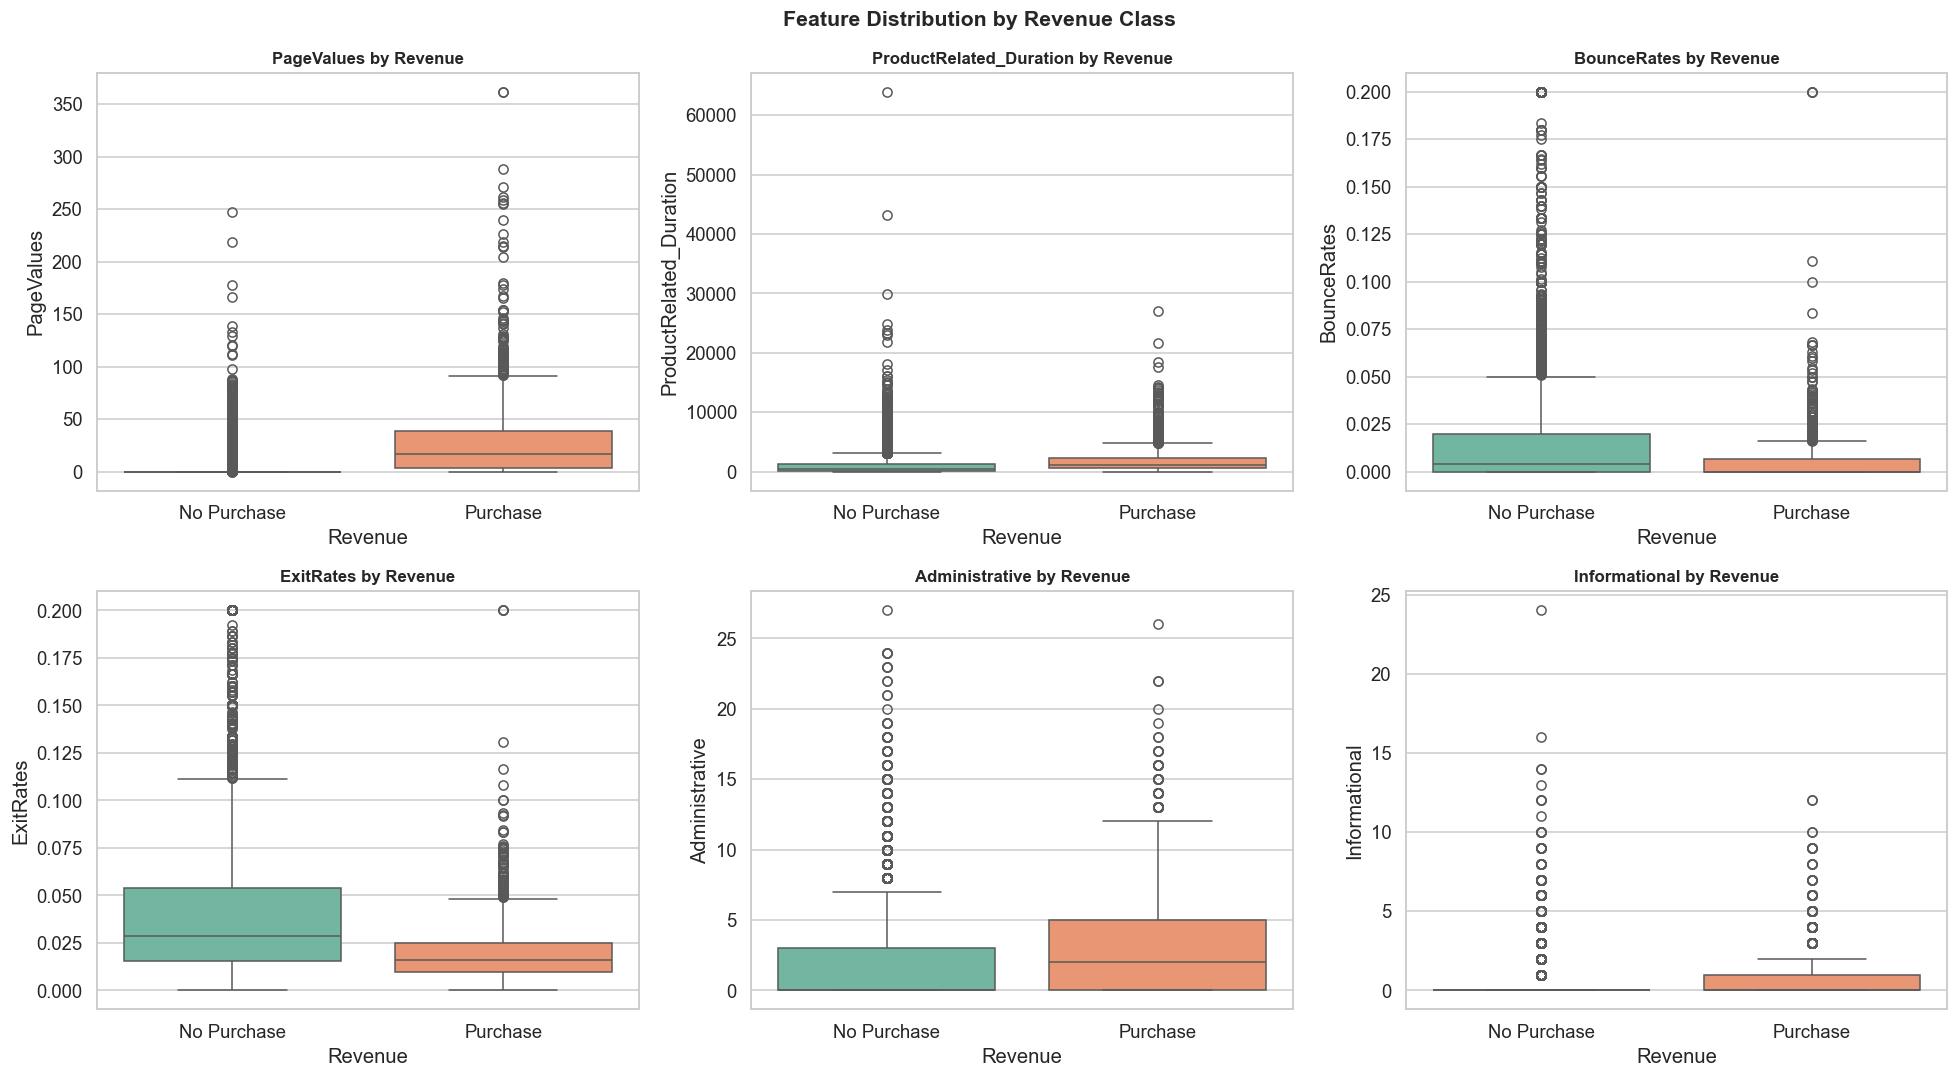

In [10]:
# ------------------------------------------------------------------
# 2.5  Feature-target relationship plots
# ------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

key_features = ['PageValues', 'ProductRelated_Duration',
                'BounceRates', 'ExitRates',
                'Administrative', 'Informational']

for i, feat in enumerate(key_features):
    df_plot = df[[feat, 'Revenue']].copy()
    df_plot['Revenue_Label'] = df_plot['Revenue'].map({False: 'No Purchase', True: 'Purchase'})
    sns.boxplot(data=df_plot, x='Revenue_Label', y=feat,
                palette='Set2', ax=axes[i])
    axes[i].set_title(f'{feat} by Revenue', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Revenue')
    axes[i].set_ylabel(feat)

fig.suptitle('Feature Distribution by Revenue Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**📝 Observation (Feature-Target Boxplots):**  
- `PageValues` shows the **most striking separation** between purchasers and non-purchasers — purchase sessions have a much higher median page value.  
- `ProductRelated_Duration` is also notably higher for purchasers — spending more time on product pages signals purchase intent.  
- `BounceRates` and `ExitRates` are slightly lower for purchasers, as expected — engaged visitors don't leave quickly.  
- These feature-target relationships confirm that `PageValues` will likely be the most important feature across classifiers.

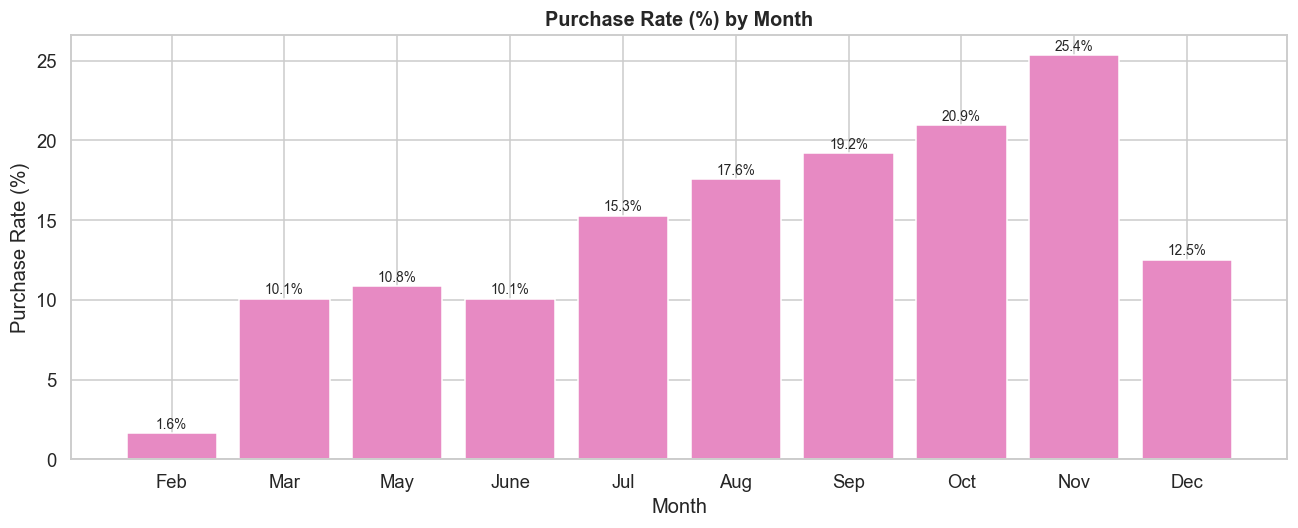

In [11]:
# ------------------------------------------------------------------
# 2.6  Purchase rate by Month
# ------------------------------------------------------------------
month_order = ['Jan','Feb','Mar','Apr','May','June','Jul','Aug','Sep','Oct','Nov','Dec']
month_order_present = [m for m in month_order if m in df['Month'].unique()]

month_stats = (df.groupby('Month')['Revenue']
               .agg(['sum', 'count'])
               .rename(columns={'sum': 'Purchases', 'count': 'Sessions'}))
month_stats['Purchase_Rate'] = (month_stats['Purchases'] / month_stats['Sessions'] * 100).round(2)
month_stats = month_stats.reindex([m for m in month_order_present if m in month_stats.index])

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(month_stats.index, month_stats['Purchase_Rate'],
              color=COLORS[3], edgecolor='white')
ax.set_title('Purchase Rate (%) by Month', fontsize=13, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Purchase Rate (%)')
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{bar.get_height():.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

**📝 Observation (Purchase Rate by Month):**  
- **November** has the highest purchase rate, reflecting seasonal holiday shopping (Black Friday, Cyber Monday).  
- **March** also shows a notably high purchase rate.  
- Some months have very few sessions (e.g., January, September) which may make their rates less reliable.  
- Month is clearly a useful predictor and should be included as a categorical feature.